# Workshop 2.1 – From data to a first scikit-learn model

Today you will explore and clean a small medical dataset, and build your first proper scikit-learn model: a linear regression that predicts body fat percentage from simple body measurements.

Work through the exercises marked ★ first: they should take about two hours.  The ★★ exercises at the end are for when you have finished.
  
### The data

Body fat percentage is a useful health indicator, but measuring it accurately is hard.  In this study, 252 men were weighed *under water*.  That gives both a person's weight and volume, giving the density of the body, and from that the body fat percentage was calculated using *Siri's equation*:

$$\text{body fat (\%)} = \frac{495}{\text{density (g/cm}^3\text{)}} - 450$$

Each individuals's age, weight and height were also recorded, as well as 10 circumferences (neck, chest, abdomen, …) measured with a tape measure.  Our question: **how well can we predict body fat from these simple measurements?**

(Penrose, Nelson and Fisher, *Medicine and Science in Sports and Exercise* 17:189, 1985; the dataset was made popular by R.W. Johnson, *Journal of Statistics Education*, 1996.)

## 0. Loading the data

Run the cell below.  It imports the modules we need and downloads the dataset from [OpenML](https://www.openml.org/d/560), a public repository of datasets.  The outcome column is called `class` there; we rename it to `BodyFat`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_openml

bodyfat = fetch_openml(data_id=560, as_frame=True).frame
bodyfat = bodyfat.rename(columns={"class": "BodyFat"})
bodyfat.head()

,Density,Age,Weight,Height,Neck,Chest,Abdomen,Hip,Thigh,Knee,Ankle,Biceps,Forearm,Wrist,BodyFat
0,1.0708,23,154.25,67.75,36.2,93.1,85.2,94.5,59.0,37.3,21.9,32.0,27.4,17.1,12.3
1,1.0853,22,173.25,72.25,38.5,93.6,83.0,98.7,58.7,37.3,23.4,30.5,28.9,18.2,6.1
2,1.0414,22,154.00,66.25,34.0,95.8,87.9,99.2,59.6,38.9,24.0,28.8,25.2,16.6,25.3
3,1.0751,26,184.75,72.25,37.4,101.8,86.4,101.2,60.1,37.3,22.8,32.4,29.4,18.2,10.4
4,1.0340,24,184.25,71.25,34.4,97.3,100.0,101.9,63.2,42.2,24.0,32.2,27.7,17.7,28.7


## 1. Exploring the data

★ Look at the data with `bodyfat.info()` and `bodyfat.describe()`.
* How many men are there, and how many columns?
* Are there any missing values?
* Which column is the outcome we want to predict?

### Units

Now check that tyou understand your data – what does each column mean?  What units are used?

★ Look at the `describe()` output again.  The circumferences (`Neck` up to `Wrist`) are in centimetres.  Can `Weight` (mean 179) and `Height` (mean 70) be in kilograms and centimetres?  What units do you think they are in?

★ Convert to metric units, as in Day 4 (no loop needed).  Add a column `Weight_kg` (1 lb = 0.4536 kg) and a column `Height_cm` (1 inch = 2.54 cm), and then drop the columns `Weight` and `Height`.

In [2]:
bodyfat[["Weight_kg", "Height_cm"]] = bodyfat[["Weight", "Height"]] * [0.453592, 2.54]

assert list(bodyfat.columns[-2:]) == ["Weight_kg", "Height_cm"]
assert round(bodyfat["Height_cm"].max(), 1) == 197.5

bodyfat.head()

,Density,Age,Weight,Height,Neck,Chest,Abdomen,Hip,Thigh,Knee,Ankle,Biceps,Forearm,Wrist,BodyFat,Weight_kg,Height_cm
0,1.0708,23,154.25,67.75,36.2,93.1,85.2,94.5,59.0,37.3,21.9,32.0,27.4,17.1,12.3,69.966566,172.085
1,1.0853,22,173.25,72.25,38.5,93.6,83.0,98.7,58.7,37.3,23.4,30.5,28.9,18.2,6.1,78.584814,183.515
2,1.0414,22,154.00,66.25,34.0,95.8,87.9,99.2,59.6,38.9,24.0,28.8,25.2,16.6,25.3,69.853168,168.275
3,1.0751,26,184.75,72.25,37.4,101.8,86.4,101.2,60.1,37.3,22.8,32.4,29.4,18.2,10.4,83.801122,183.515
4,1.0340,24,184.25,71.25,34.4,97.3,100.0,101.9,63.2,42.2,24.0,32.2,27.7,17.7,28.7,83.574326,180.975


### Looking for errors

★ Make a histogram of every column, with a `for` loop over `bodyfat.columns`.  Use `sns.histplot(bodyfat[col])` and `plt.show()` after each plot (as on Day 5).

Look for values that are biologically impossible, or far outside the rest of the distribution.  Write down what you find for `Height_cm`, `BodyFat` and `Ankle`.

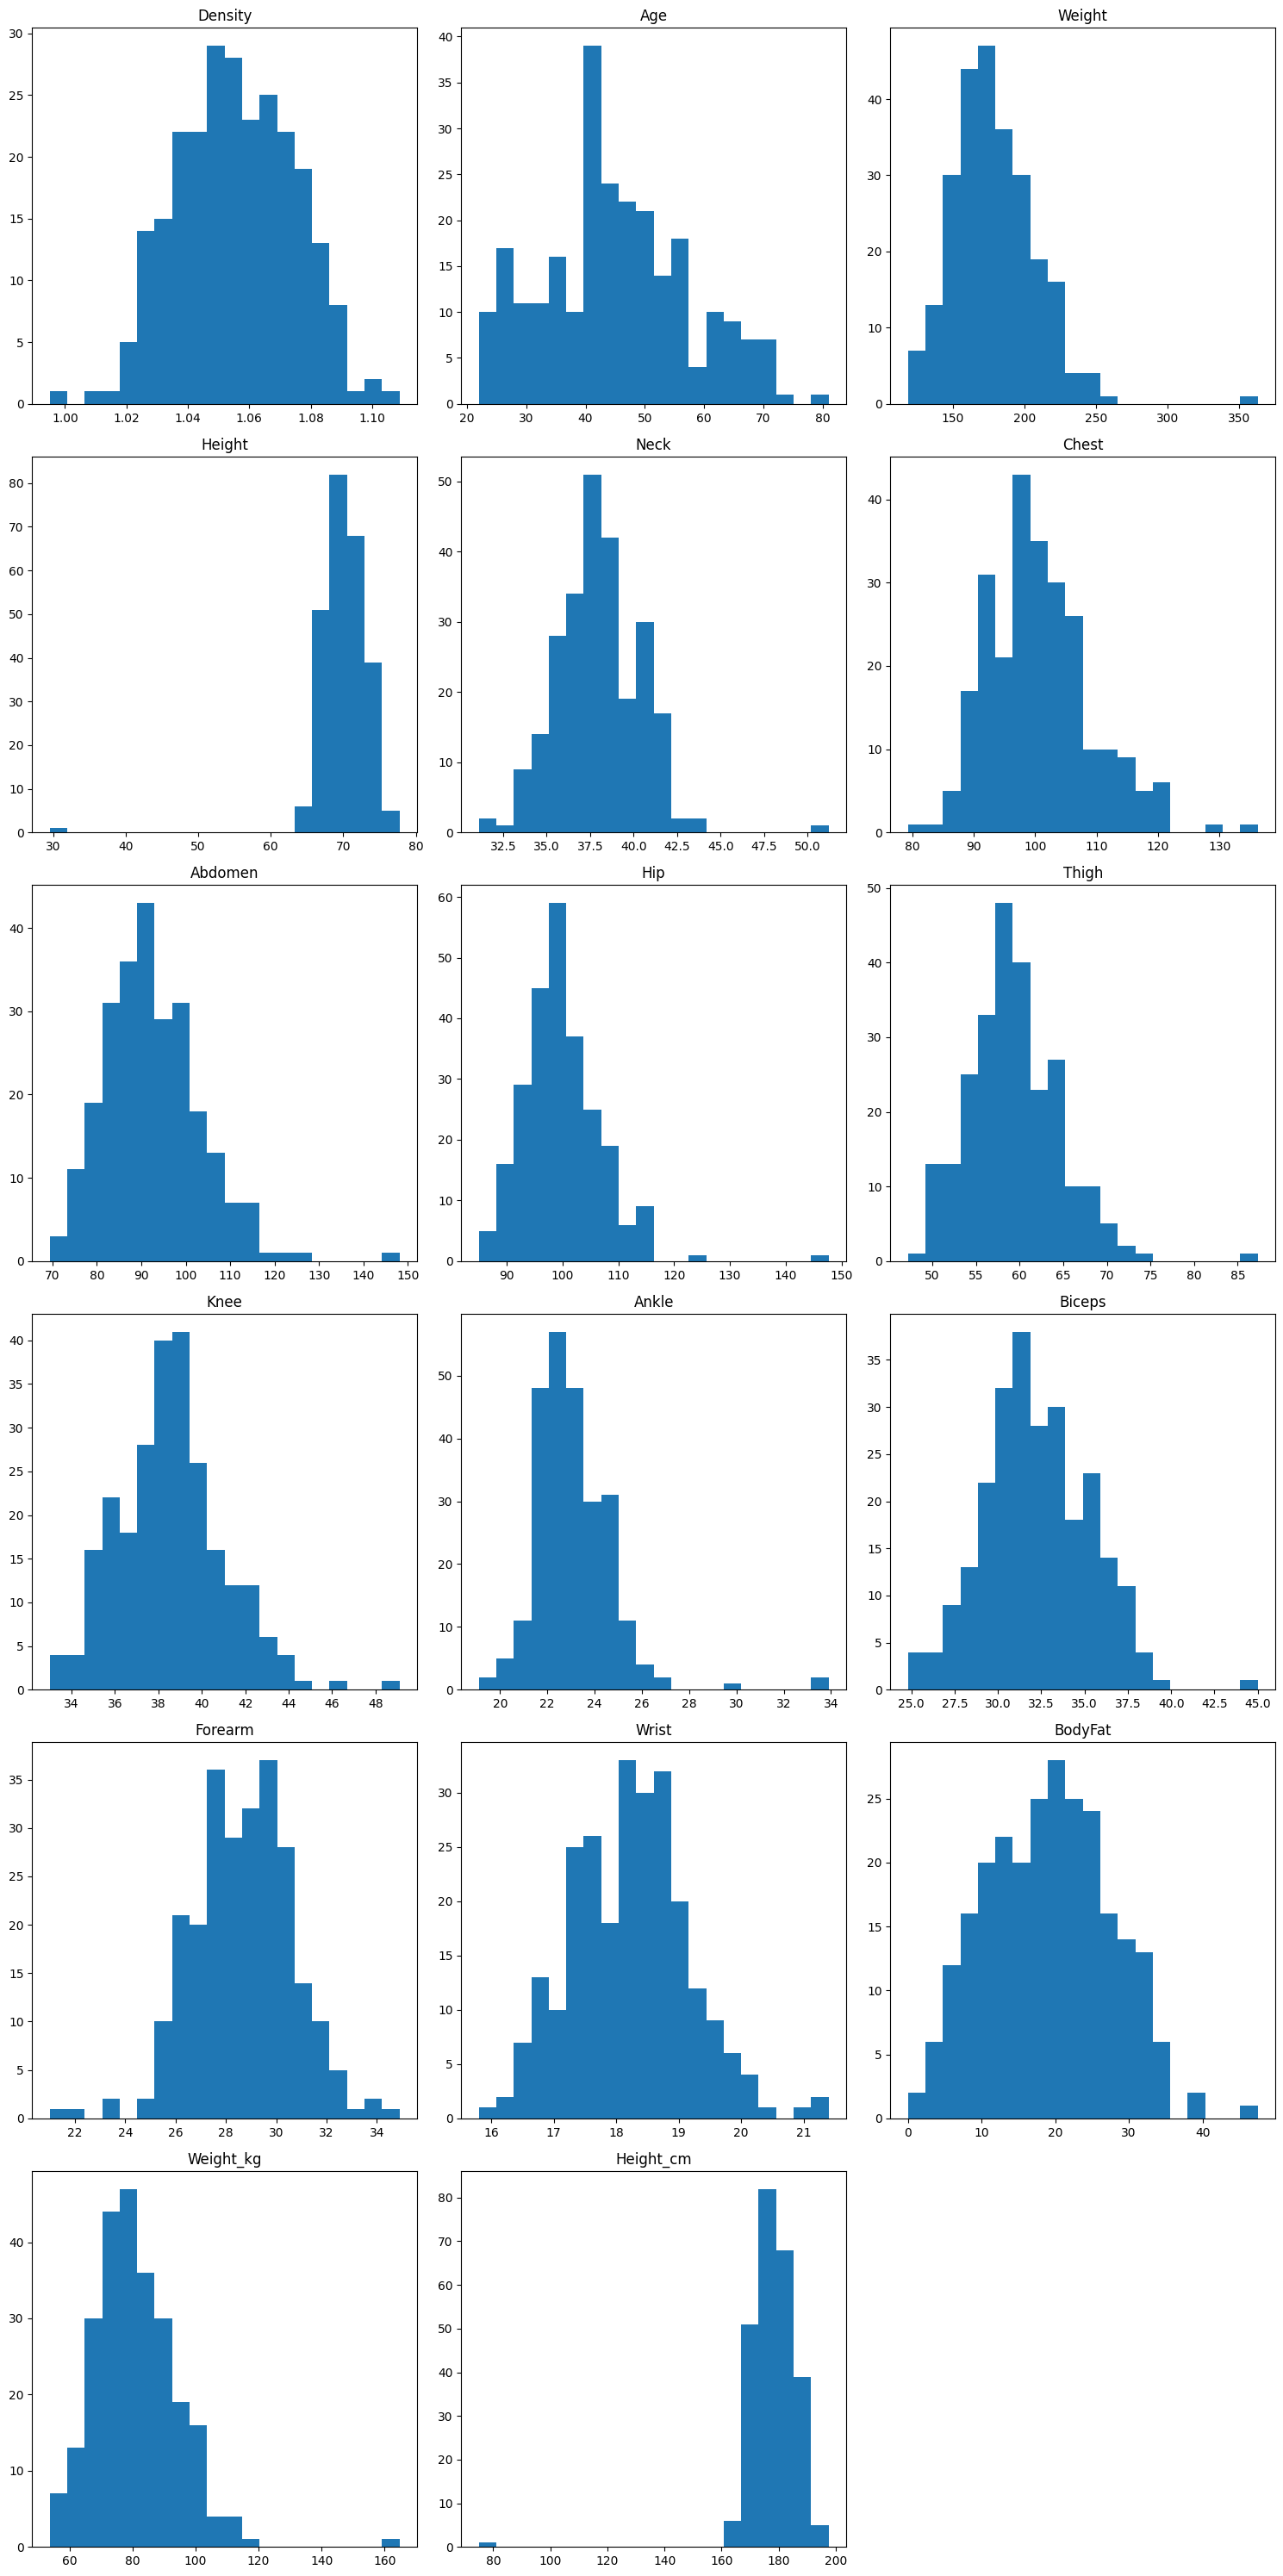

In [3]:
import math

cols = bodyfat.columns
ncols_plt = 3
nrows = math.ceil(len(cols) / ncols_plt)
# Set overarching plot, with nrows and ncols_plt
fig, axes = plt.subplots(nrows, ncols_plt, figsize=(15, nrows * 5))
# Flatten the axes array for easy iteration
axes = axes.flatten()

for ax, col in zip(axes, cols):
    ax.hist(bodyfat[col], bins = 20)
    ax.set_title(col)

for ax in axes[len(cols):]:
    ax.set_visible(False)
plt.tight_layout()


★ Use Boolean indexing to show the suspicious rows: the men shorter than 100 cm, the men with a body fat below 2%, and the men with an ankle circumference above 32 cm.
* Is a man of 75 cm and 93 kg plausible?
* Men need at least 2–5% of "essential" body fat to survive.  
* Compare the two entries with large ankle circumference with the rest of those men's measurements.  What may have happened?

In [4]:
bodyfat["plausible height"] = bodyfat["Height_cm"].gt(100)
bodyfat["plausible bodyfat"] = bodyfat["BodyFat"].gt(2)

bodyfat.head(10)

bodyfat["Ankle"].nlargest(2).tolist()
top2 = bodyfat.nlargest(2, "Ankle")
others = bodyfat.drop(top2.index)


comparison = top2.mean() - others.mean()
comparison["others_mean"] = others.mean(numeric_only = True)
comparison["top2_mean"] = top2.mean(numeric_only = True)

print(comparison)
comparison_tbl = pd.DataFrame(["Top 2 mean: " + str(comparison["top2_mean"]), "Others mean: " + str(comparison["others_mean"])])
print(f"Top 2 mean: {comparison['top2_mean']}")
print(f"Others mean: {comparison['others_mean']}")
print(comparison_tbl)


Density                                                      -0.000478
Age                                                              4.652
Weight                                                         -4.4598
Height                                                            0.48
Neck                                                           -0.3952
Chest                                                          -1.1332
Abdomen                                                        -3.3828
Hip                                                              -1.92
Thigh                                                          -3.3324
Knee                                                           -0.3432
Ankle                                                          10.7832
Biceps                                                           0.178
Forearm                                                        -0.9716
Wrist                                                           0.0708
BodyFa

### Checking the outcome

`BodyFat` was calculated from `Density` with Siri's equation (see the top of this notebook).  We can check this.

★ Compute `siri = 495 / bodyfat["Density"] - 450`, and make a Boolean Series `mismatch` that is `True` where `BodyFat` and `siri` differ by more than 1 percentage point (use `.abs()`).  Print `mismatch.sum()`, and show the `Density` and `BodyFat` values of these men next to `siri`.

In [5]:
siri = 495 / bodyfat["Density"] - 450
mismatch = abs(bodyfat["BodyFat"] - siri) > 1

assert mismatch.sum() == 5

For these 5 men, either the density or the body fat was recorded wrongly, and we cannot tell which.

## 2. Cleaning the data

The slides suggest different treatments for errors in the **outcome** and errors in the **predictors**:
* If the *outcome* is wrong or missing, we cannot use that man to train or test a model: remove the row.
* If a *predictor* is wrong, replace it by a missing value (`np.nan`), and fill it in later (*imputation*).  That way we keep the rest of that man's measurements.

Before cleaning, we keep an unchanged copy, `raw`, to compare with later.

In [6]:
raw = bodyfat.copy()

★ Remove the rows with a body fat below 2%, and the rows where `mismatch` is `True`.  (Hint: combine the two conditions with `|`, and keep the rows where the combination is **not** true, with `~`.)  How many men are left?

In [7]:
bodyfat.drop(bodyfat[bodyfat["BodyFat"] < 2].index, inplace=True)
siri = 495 / bodyfat["Density"] - 450
mismatch = abs(bodyfat["BodyFat"] - siri) > 1
bodyfat["mismatch"] = mismatch
bodyfat.drop(bodyfat[bodyfat["mismatch"] == True].index, inplace=True)
print(len(bodyfat))

assert len(bodyfat) == 246

246


★ Replace the impossible height and the two impossible ankle circumferences by `np.nan`.  Use `.loc[rows, column] = np.nan`, as in Day 4.  Then count the missing values per column with `bodyfat.isna().sum()`.

In [8]:
# impossible height (the one below 100 cm)
bodyfat.loc[bodyfat["Height_cm"] < 100, "Height_cm"] = np.nan
bodyfat.loc[bodyfat["Ankle"] > 30, "Ankle"] = np.nan


print(bodyfat.isna().sum())

assert bodyfat.isna().sum().sum() == 3

Density              0
Age                  0
Weight               0
Height               0
Neck                 0
Chest                0
Abdomen              0
Hip                  0
Thigh                0
Knee                 0
Ankle                2
Biceps               0
Forearm              0
Wrist                0
BodyFat              0
Weight_kg            0
Height_cm            1
plausible height     0
plausible bodyfat    0
mismatch             0
dtype: int64


### Predictors and outcome

Scikit-learn wants the predictors in one table, usually called `X`, and the outcome in a separate Series, usually called `y`.

Think about `Density`: should it be one of the predictors?  Remember how `BodyFat` was calculated, and what our question was.

★ Make `X` with all columns except `BodyFat` and `Density`, and `y` with just `BodyFat`.

In [9]:
print(bodyfat.head())

X = bodyfat.drop(columns=["BodyFat", "Density", "Height", "Weight", "plausible height", "plausible bodyfat", "mismatch"])
y = bodyfat["BodyFat"]

print(X.shape)
print(y.shape)

assert X.shape == (246, 13)
assert y.name == "BodyFat"

   Density  Age  Weight  Height  Neck  Chest  Abdomen    Hip  Thigh  Knee  \
0   1.0708   23  154.25   67.75  36.2   93.1     85.2   94.5   59.0  37.3   
1   1.0853   22  173.25   72.25  38.5   93.6     83.0   98.7   58.7  37.3   
2   1.0414   22  154.00   66.25  34.0   95.8     87.9   99.2   59.6  38.9   
3   1.0751   26  184.75   72.25  37.4  101.8     86.4  101.2   60.1  37.3   
4   1.0340   24  184.25   71.25  34.4   97.3    100.0  101.9   63.2  42.2   

   Ankle  Biceps  Forearm  Wrist  BodyFat  Weight_kg  Height_cm  \
0   21.9    32.0     27.4   17.1     12.3  69.966566    172.085   
1   23.4    30.5     28.9   18.2      6.1  78.584814    183.515   
2   24.0    28.8     25.2   16.6     25.3  69.853168    168.275   
3   22.8    32.4     29.4   18.2     10.4  83.801122    183.515   
4   24.0    32.2     27.7   17.7     28.7  83.574326    180.975   

   plausible height  plausible bodyfat  mismatch  
0              True               True     False  
1              True             

## 3. The scikit-learn model object, step by step

### Training and test data

As in the slides, we *fit* the model on training data, and *score* it on test data that the model has never seen.  `train_test_split` splits `X` and `y` at random, keeping the rows of `X` and `y` together.  Setting `random_state` makes the split the same each time you run it.

★ Run the cell, and check the sizes of the four parts.

In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(184, 13) (62, 13) (184,) (62,)


★ Run the cell below.  It tries to fit a linear regression model on the training data.  Read the error message from the bottom up: what is the problem?

In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
#model.fit(X_train, y_train)

ValueError: Input X contains NaN.
LinearRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

### Imputation: a first example of `fit`

A `SimpleImputer` fills in missing values.  Like a model, it has a `fit` method: `fit` *learns* from the training data what to fill in.  For `strategy="median"` it learns the median of each column, and stores these in `imputer.statistics_`.  The method `transform` then fills in the missing values.

★ Make an imputer using `imputer = SimpleImputer(strategy="median")` and fit it on `X_train`.  Show the learned medians as a Series: `pd.Series(imputer.statistics_, index=X.columns)`.  Check that they are the same as `X_train.median()`.

In [25]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy= "median")
imputer.fit(X_train)
X_train_imp = imputer.transform(X_train)
X_test_imp = imputer.transform(X_test)
print(X_train_imp)
print(X_test_imp)
print(X_train.median())


assert np.allclose(imputer.statistics_, X_train.median())

[[ 43.        39.6      104.       ...  17.7       80.285784 175.895   ]
 [ 44.        37.9      100.8      ...  18.4       83.460928 187.96    ]
 [ 42.        38.3       96.2      ...  17.7       74.956078 177.165   ]
 ...
 [ 47.        37.3       99.6      ...  17.8       83.574326 189.23    ]
 [ 40.        39.4       89.5      ...  18.2       75.97666  181.61    ]
 [ 43.        31.1       93.1      ...  18.8       75.069476 173.99    ]]
[[ 41.         39.8       111.7       100.5       108.3        67.1
   44.2        25.2        37.5        31.5        18.7        99.109852
  180.34     ]
 [ 26.         36.4       105.1        90.7       100.3        58.4
   38.3        22.9        31.9        27.8        17.7        82.100152
  177.165    ]
 [ 41.         38.5       107.4        98.9       104.1        63.5
   39.8        23.5        36.4        30.4        19.1        95.481116
  182.88     ]
 [ 46.         38.         97.3        86.         99.3        61.
   38.4        23.8  

★ Use `imputer.transform` to make `X_train_imp` and `X_test_imp`.  Note that the test data are filled in with the medians of the **training** data: the test data are not used to fit anything.  `transform` returns a NumPy array; check with `np.isnan(...).sum()` that no missing values are left.

In [26]:
assert np.isnan(X_train_imp).sum() == 0 and np.isnan(X_test_imp).sum() == 0

### `fit`: learning the parameters

★ Fit `model` (the `LinearRegression` from before) on `X_train_imp` and `y_train`.  The fitted parameters are stored in `model.intercept_` and `model.coef_`.  Print the intercept, and the coefficients as a Series with the column names as index.

In [28]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train_imp, y_train)

intercept = pd.Series(model.intercept_, index=["intercept"])
coef = pd.Series(model.coef_, index=X_train.columns)

print(intercept, coef)

assert len(model.coef_) == 13

intercept    16.435046
dtype: float64 Age          0.041929
Neck        -0.330213
Chest       -0.135065
Abdomen      0.963114
Hip         -0.265578
Thigh        0.114865
Knee        -0.008013
Ankle        0.050092
Biceps       0.237432
Forearm      0.103833
Wrist       -1.764386
Weight_kg    0.016774
Height_cm   -0.128355
dtype: float64


The coefficient of `Abdomen` tells you how much the predicted body fat goes up (in percentage points) for each extra centimetre of waist, *if all other measurements stay the same*.

★ What is the coefficient of `Abdomen`?  Does it make sense?  Some coefficients, like that of `Weight_kg`, are negative.  Can you think of a reason?  (Hint: two men with the same waist, chest, hips, … but different weights.)

### `predict`: using the parameters

★ Use `model.predict(X_test_imp)` to predict the body fat of the men in the test set.  Show the first 10 predictions next to the true values, in a DataFrame with columns `true` and `predicted`.  Then check that `predict` did not change the parameters: is `model.coef_` still the same as `coefs`?

In [37]:
y_prediction = model.predict(X_test_imp)


prediction = pd.DataFrame({"prediction": y_prediction[:10], "true": y_test.values[:10]}, index=range(10))

same_coefs = pd.DataFrame({"model": model.coef_, "coef": coef, "Similar": abs(model.coef_)-abs(coef) < 0.01})

print(same_coefs)
assert len(y_prediction) == len(y_test)

              model      coef  Similar
Age        0.041929  0.041929     True
Neck      -0.330213 -0.330213     True
Chest     -0.135065 -0.135065     True
Abdomen    0.963114  0.963114     True
Hip       -0.265578 -0.265578     True
Thigh      0.114865  0.114865     True
Knee      -0.008013 -0.008013     True
Ankle      0.050092  0.050092     True
Biceps     0.237432  0.237432     True
Forearm    0.103833  0.103833     True
Wrist     -1.764386 -1.764386     True
Weight_kg  0.016774  0.016774     True
Height_cm -0.128355 -0.128355     True


### `score`: comparing predictions with the truth

For a regression model, `score` gives R², the proportion of the variance of `y` that the model explains:

$$R^2 = 1 - \frac{\sum_i (y_i - \hat y_i)^2}{\sum_i (y_i - \bar y)^2}$$

Here $\bar y$ is the mean of the observations.  R² = 1 means perfect predictions; R² = 0 means no better than always predicting the mean.

★ Compute `model.score(X_test_imp, y_test)`.  Then compute R² yourself from `y_test` and `y_pred`, using the formula above, and check that you get the same number.  Do not use a `for` loop but use `numpy`'s methods to calculate the sums.

In [39]:
model.score(X_test_imp, y_test)
r2_by_hand = 1 - np.sum((y_test - y_prediction)**2) / np.sum((y_test - np.mean(y_test))**2)

print(r2_by_hand)

assert np.isclose(r2_by_hand, model.score(X_test_imp, y_test))

0.6508464667871774


R² is hard to interpret on its own.  Another way to see how good the model is: by how many percentage points is the prediction off, on average?

★ Compute the mean absolute error, `(y_test - y_pred).abs().mean()`.

In [40]:
mean_abs_error = np.mean(np.abs(y_test - y_prediction))
print(mean_abs_error)

3.4191149889108


The mean absolute error is often an optimistic measure - it tends to obscure occasional large errors.  A better measure is the root mean squared error, the standard deviation of the residual.  (This measure is directly related to the loss function that a `LinearRegression` model is optimizing.)

★ Compute the root-mean-squared error, `np.sqrt((y_test - y_pred).var())`

In [44]:
mean_squared_error = np.sqrt(((y_test - y_prediction)**2).mean())
original = np.sqrt((y_test - y_prediction).var())
print(model.score(X_test_imp, y_test))
print(mean_squared_error)
print(original)

0.6508464667871774
4.463525545466028
4.460941570303821


★ Is a model with 13 measurements much better than a model with just one?  Fit a new `LinearRegression` that uses only `Abdomen` (use `X_train[["Abdomen"]]`; this column has no missing values, so no imputer is needed), and compute its R² on the test data.

In [47]:
model2 = LinearRegression().fit(X_train[["Abdomen"]], y_train)
y_prediction = model2.predict(X_test[["Abdomen"]])
abdomen_r2 = np.sqrt((y_test - y_prediction).var())
abdomen_r2_2 = model2.score(X_test[["Abdomen"]], y_test)

print(abdomen_r2)
print(abdomen_r2_2)

assert 0.4 < abdomen_r2_2 < 0.8

5.002030835438285
0.556921895530472


## 4. A pipeline

Above, we called `fit` twice (imputer and model), and `transform` twice.  With more preprocessing steps this becomes error-prone: it is easy to forget a step, or to accidentally fit a step on the test data.  A **pipeline** chains the steps together into a single model, with the same `fit`, `predict` and `score` methods:

```
from sklearn.pipeline import make_pipeline
pipe = make_pipeline(SimpleImputer(strategy="median"), LinearRegression())
```

`pipe.fit(X_train, y_train)` fits the imputer on `X_train`, transforms `X_train`, and fits the regression on the result.  `pipe.predict(X_test)` transforms `X_test` with the *fitted* imputer, and then predicts.

★ Make this pipeline, fit it on `X_train` and `y_train` (the data with missing values!), and compute its score on the test data.  Is it the same as before?

In [ ]:
from sklearn.pipeline import make_pipeline



assert np.isclose(pipe.score(X_test, y_test), model.score(X_test_imp, y_test))

You can look inside a pipeline: `pipe[0]` is the first step (the imputer) and `pipe[-1]` the last step (the regression).

★ Print the medians learned by the imputer in `pipe`, and the coefficients of the regression in `pipe`.

### Predicting for a new individual

★ Another individual had all his measurements taken, except his ankle circumference.  Run the cell to make a one-row DataFrame with his data, and use `pipe.predict` to predict his body fat.  What does the pipeline do with the missing ankle measurement?

In [ ]:
new_person = pd.DataFrame({"Age": [35], "Neck": [38.0], "Chest": [100.0], "Abdomen": [90.0],
                        "Hip": [100.0], "Thigh": [59.0], "Knee": [38.5], "Ankle": [np.nan],
                        "Biceps": [32.0], "Forearm": [28.7], "Wrist": [18.2],
                        "Weight_kg": [80.0], "Height_cm": [178.0]})
new_person

In [ ]:



assert 10 < new_prediction[0] < 25

### What does one error do to the model?

In the lecture I mentioned that outliers can have large influence on the final model.  Let's check this for the man whose height was recorded as 75 cm.

For simplicity we use two predictors, `Weight_kg` and `Height_cm`, and look at the fitted parameters only, so we fit on all the data (no test set needed).

★ Fit `make_pipeline(SimpleImputer(strategy="median"), LinearRegression())` twice:
1. on `X[["Weight_kg", "Height_cm"]]` and `y` (the cleaned data, with the wrong height replaced by NaN);
2. on the same columns and rows of `raw`, which still contains the wrong height: `raw.loc[X.index, ["Weight_kg", "Height_cm"]]`.

Compare the coefficients of `Height_cm`.  How much does one wrong number change the model?

In [ ]:
assert abs(clean_coef) > 1.5 * abs(raw_coef)

### How reliable is the score?

★ Go back to section 3 and copy the code for making a train/test split.  Repeat the train/test split and the pipeline for `random_state` = 0, 1, 2, 3 and 4 (use a `for` loop), fit the pipeline, and print the **test** score each time.  How much does the score vary?  If you compared two models using a single split, how confident could you be that one is really better than the other?

(Tomorrow we will discuss *cross validation*, which addresses exactly this problem.)

---
## ★★ Challenges

### Scaling
The slides recommend scaling each predictor to mean 0 and variance 1, with `StandardScaler` (from `sklearn.preprocessing`).
1. Add a `StandardScaler()` to the pipeline, between the imputer and the regression.  Fit it on the training data and compute the test score.  Does the score change much?  Why (not)?  (Hint: what happens to the prediction if you measure the abdomen in metres instead of centimetres?)
2. Compare the coefficients with and without scaling.  What does a coefficient mean after scaling?  Which measurement now has the largest coefficient (in absolute value)?

### The best single measurement
Which single measurement predicts body fat best?  Use a `for` loop over the columns of `X`.  For each column, fit `make_pipeline(SimpleImputer(strategy="median"), LinearRegression())` on that column only (`X_train[[col]]`), and store its test score in a dictionary.  Print the columns sorted by score.  Are you surprised by the top 3?

### Mean or median?
Replace `strategy="median"` by `strategy="mean"` in the pipeline.  Does the score change?  Only 3 values are missing; can you think of a dataset where the choice would matter much more?